# Tries vs. B-Trees

- A **trie** uses one node per *character*, a list of nodes make up the word. 
  
- A **B-tree** uses one node per *word/number* and packs several
  keys into each node to keep the tree short

In [27]:
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML, display
import copy
import math

# Let animation output embed in the notebook even for the bigger scenes.
matplotlib.rcParams['animation.embed_limit'] = 100  # MB

# Shared palette, used consistently across every scene.
COLOR = {
    'idle':      '#dcdde1',   # untouched node / edge
    'idle_edge': '#b2bec3',
    'reuse':     '#27ae60',   # trie: path segment that already existed
    'new':       '#e67e22',   # newly created node/edge, or "currently visiting"
    'end':       '#2c6fa8',   # trie: node that completes a word
    'fail':      '#c0392b',   # a lookup miss
    'text_dark': '#2d3436',
}

def show_animation(ani, fig):
    """Render a FuncAnimation inline and close the figure to avoid a duplicate static plot."""
    html = HTML(ani.to_jshtml())
    plt.close(fig)
    display(html)


## The shared dataset

These set of words will be used for all the followingexamples.

```
car, cart, care, cat, dog, dot, do, tea, ten, to
```

It's small enough to stay readable also has overlaping words, that will make understanding tries easier. 

In [28]:
WORDS = ["car", "cart", "care", "cat", "dog", "dot", "do", "tea", "ten", "to"]
WORDS

['car', 'cart', 'care', 'cat', 'dog', 'dot', 'do', 'tea', 'ten', 'to']

## Part 0 — A binary search tree (BST)

Before looking at tries and B-trees, let's start with BST

A **binary search tree (BST)** stores **one key per node** and gives each
node **at most two children**, with one rule:

> everything in a node's **left** subtree is *smaller* than its key,
> everything in its **right** subtree is *larger*.

- **Search:** start at the root, compare, go left or right, repeat. You
  either land on the key or fall off the bottom (a miss).
- **Insert:** do the same search; the empty spot where you fall off is
  exactly where the new key gets inserted.
- **Cost:** one comparison per level, so every step costs the tree's
  *height*. A nicely balanced tree has height about `log₂(N)`, but a
  plain BST does nothing to *keep* itself balanced.

Below is a tiny example with seven numbers: `50, 30, 70, 20, 40, 60, 80`.

In [29]:
class BSTNode:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None


class BST:
    def __init__(self):
        self.root = None

    def insert(self, key):
        """Insert key; return the keys compared on the way down (the search path)."""
        if self.root is None:
            self.root = BSTNode(key)
            return []
        path, node = [], self.root
        while True:
            path.append(node.key)
            side = 'left' if key < node.key else 'right'
            nxt = getattr(node, side)
            if nxt is None:
                setattr(node, side, BSTNode(key))
                return path
            node = nxt

    def search(self, key):
        """Return (keys visited, found?)."""
        path, node = [], self.root
        while node is not None:
            path.append(node.key)
            if key == node.key:
                return path, True
            node = node.left if key < node.key else node.right
        return path, False

    def height(self):
        def h(n):
            return 0 if n is None else 1 + max(h(n.left), h(n.right))
        return h(self.root)


def layout_bst(root):
    """x = in-order rank (so the drawing reads sorted left to right), y = -depth."""
    positions, edges, counter = {}, [], [0]

    def walk(node, depth):
        if node is None:
            return
        walk(node.left, depth + 1)
        positions[node.key] = (counter[0], -depth)
        counter[0] += 1
        walk(node.right, depth + 1)
        for child in (node.left, node.right):
            if child is not None:
                edges.append((node.key, child.key))

    walk(root, 0)
    return positions, edges


def draw_bst(ax, positions, edges, present, path=None, new=None, found=None,
             fail=None, title=""):
    """Draw the keys in `present`. path = compared on the way down (green),
    new = just inserted (orange), found = search hit (blue), fail = last node before a miss (red)."""
    ax.clear()
    path = set(path or [])
    for a, b in edges:
        if a not in present or b not in present:
            continue
        on_path = a in path and (b in path or b == new or b == found)
        ax.plot(*zip(positions[a], positions[b]),
                color=COLOR['reuse'] if on_path else COLOR['idle_edge'],
                lw=3.5 if on_path else 1.5, zorder=1, solid_capstyle='round')
    for k in present:
        x, y = positions[k]
        if k == fail:
            fc = COLOR['fail']
        elif k == new:
            fc = COLOR['new']
        elif k == found:
            fc = COLOR['end']
        elif k in path:
            fc = COLOR['reuse']
        else:
            fc = COLOR['idle']
        ax.add_patch(plt.Circle((x, y), 0.4, facecolor=fc, edgecolor='black', linewidth=1, zorder=2))
        label = str(k)
        ax.text(x, y, label, ha='center', va='center', fontweight='bold', zorder=3,
                fontsize=11 if len(label) <= 2 else 8.5,
                color=COLOR['text_dark'] if fc == COLOR['idle'] else 'white')
    ax.set_title(title, fontsize=13)
    xs = [p[0] for p in positions.values()]
    ys = [p[1] for p in positions.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 0.8, 0.8)
    ax.set_aspect('equal')
    ax.axis('off')

### Scene 0 — Building a small BST, then searching it

Same color language as the rest of the notebook: **green** is a node the
new key is compared against on the way down, **orange** is the node just
created, **blue** is a successful search hit, **red** is where a search
falls off the tree. After the seven inserts we search for `60` (a hit)
and `65` (a miss).

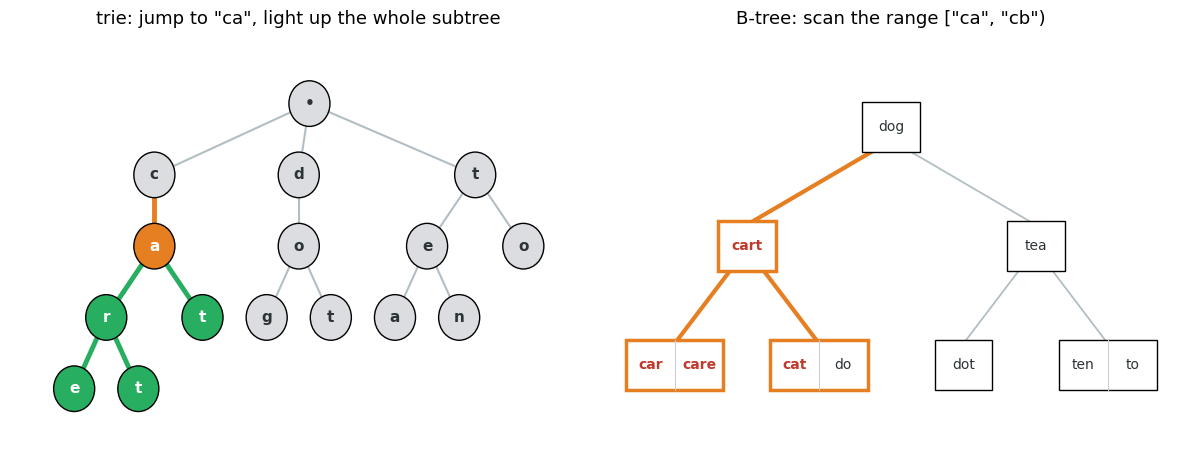

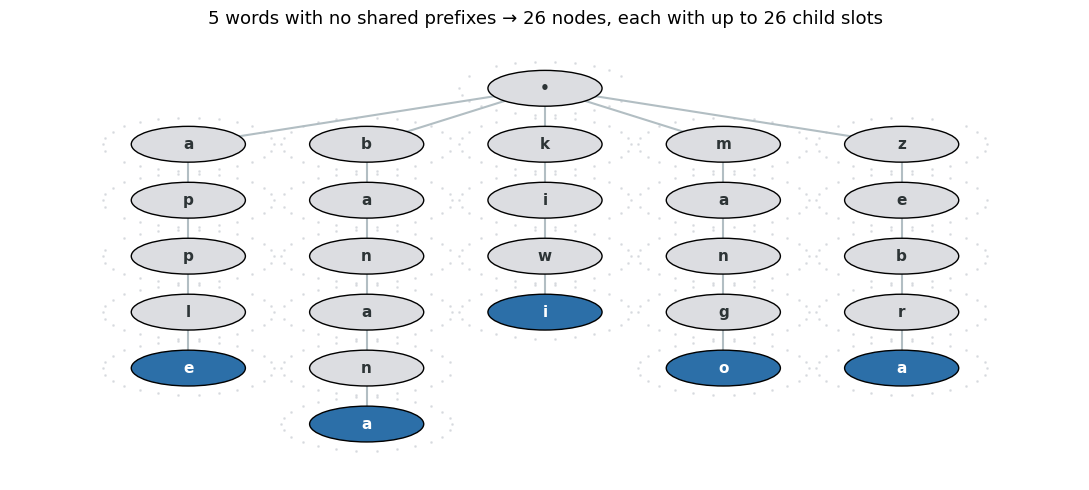

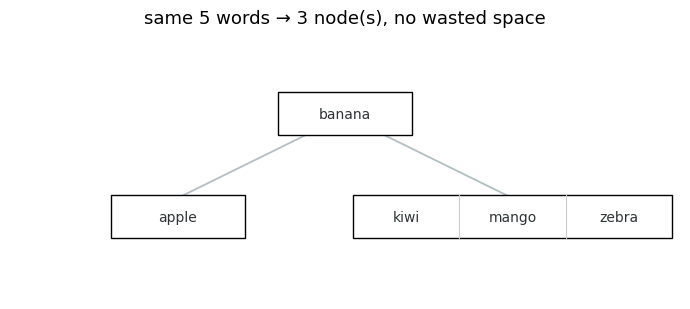

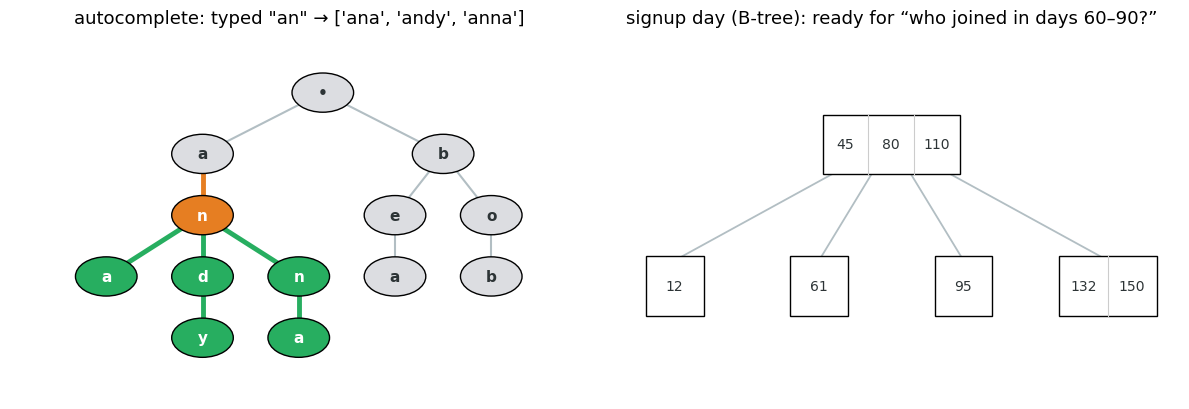

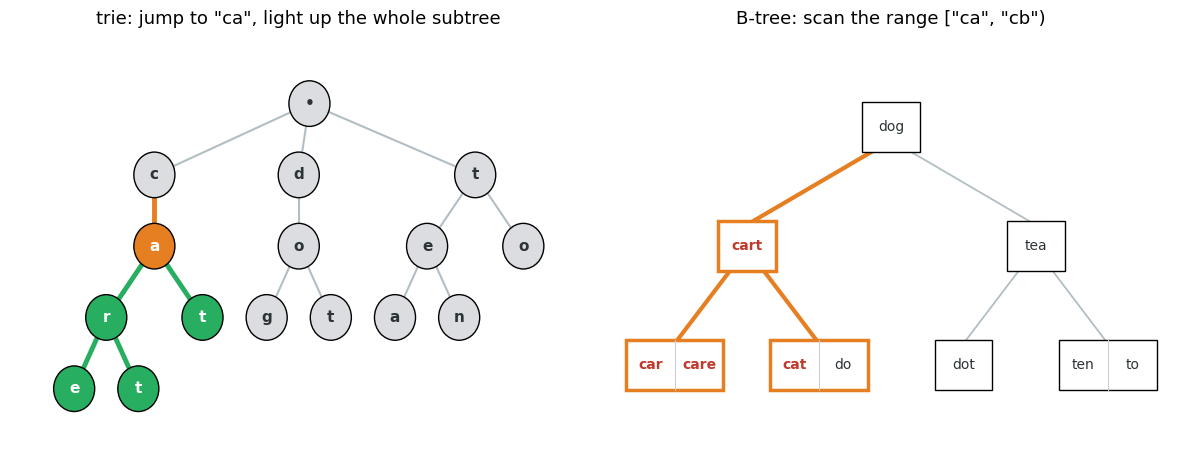

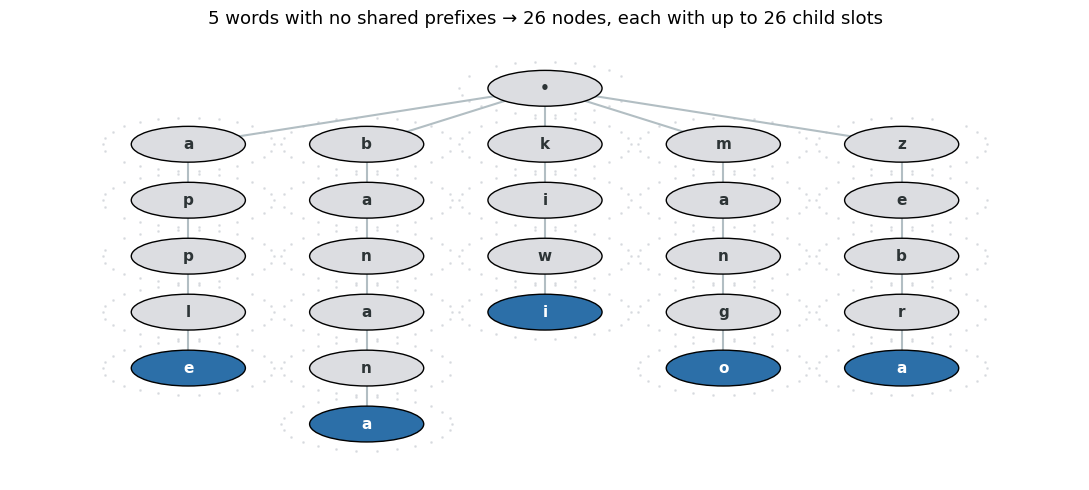

In [30]:
NUMS = [50, 30, 70, 20, 40, 60, 80]

num_bst = BST()
bst_frames, present = [], []
for k in NUMS:
    path = num_bst.insert(k)
    # one frame per comparison on the way down, then one showing the new node
    for i in range(1, len(path) + 1):
        bst_frames.append(dict(present=list(present), path=path[:i],
                               title=f"inserting {k}: compare with {path[i-1]}"))
    present.append(k)
    where = "as the root" if not path else \
            f"as the {'left' if k < path[-1] else 'right'} child of {path[-1]}"
    bst_frames.append(dict(present=list(present), path=path, new=k, title=f"{k} inserted {where}"))

for target in (60, 65):
    path, hit = num_bst.search(target)
    for i in range(1, len(path) + 1):
        bst_frames.append(dict(present=present, path=path[:i],
                               title=f"search {target}: compare with {path[i-1]}"))
    if hit:
        bst_frames.append(dict(present=present, path=path[:-1], found=target,
                               title=f"search {target}: found after {len(path)} comparisons"))
    else:
        bst_frames.append(dict(present=present, path=path[:-1], fail=path[-1],
                               title=f"search {target}: no child to go to — not in the tree"))

bst_positions, bst_edges = layout_bst(num_bst.root)
fig0, ax0 = plt.subplots(figsize=(8, 4.2))

def update_bst(i):
    f = bst_frames[i]
    draw_bst(ax0, bst_positions, bst_edges, f['present'], f.get('path'), f.get('new'),
             f.get('found'), f.get('fail'), title=f['title'])

ani0 = animation.FuncAnimation(fig0, update_bst, frames=len(bst_frames), interval=600)
show_animation(ani0, fig0)

Seven keys, three levels, and any lookup costs at most three comparisons.
That's the *best case* — it only happened because the insertion order
(`50` first, then the middle of each half) kept the tree balanced.

### Scene 0b — The same ten words in a BST

`car, cart, care, cat, dog, dot, do, tea, ten, to`, this dataset is inserted in that
order. Words are compared alphabetically (`"care" < "cart"` because
`e < t`), so the same left/right rule applies. After building it, we
search for `"cart"` 

Note how lopsided and unbalanced it gets: `car` is the root and every later word is
alphabetically larger, so the whole tree hangs off the root's right side
and leans further right as `dog`, `dot`, `tea`, `ten`, `to` arrive.

In [31]:
word_bst = BST()
word_bst_frames, present = [], []
for w in WORDS:
    path = word_bst.insert(w)
    for i in range(1, len(path) + 1):
        side = 'left' if w < path[i-1] else 'right'
        word_bst_frames.append(dict(present=list(present), path=path[:i],
                                    title=f'inserting "{w}": vs "{path[i-1]}" → go {side}'))
    present.append(w)
    where = "as the root" if not path else \
            f"as the {'left' if w < path[-1] else 'right'} child of \"{path[-1]}\""
    word_bst_frames.append(dict(present=list(present), path=path, new=w,
                                title=f'"{w}" inserted {where}'))

BST_QUERY = "cart"
q_path, q_hit = word_bst.search(BST_QUERY)
for i in range(1, len(q_path) + 1):
    word_bst_frames.append(dict(present=present, path=q_path[:i],
                                title=f'search "{BST_QUERY}": compare with "{q_path[i-1]}"'))
word_bst_frames.append(dict(present=present, path=q_path[:-1], found=BST_QUERY if q_hit else None,
                            fail=None if q_hit else q_path[-1],
                            title=f'search "{BST_QUERY}": {"found" if q_hit else "not found"} '
                                  f'after {len(q_path)} comparisons'))

word_bst_positions, word_bst_edges = layout_bst(word_bst.root)
fig0w, ax0w = plt.subplots(figsize=(9, 6))

def update_word_bst(i):
    f = word_bst_frames[i]
    draw_bst(ax0w, word_bst_positions, word_bst_edges, f['present'], f.get('path'), f.get('new'),
             f.get('found'), f.get('fail'), title=f['title'])

ani0w = animation.FuncAnimation(fig0w, update_word_bst, frames=len(word_bst_frames), interval=600)
show_animation(ani0w, fig0w)

print(f"BST over WORDS: height {word_bst.height()}, "
      f'search "{BST_QUERY}" took {len(q_path)} whole-word comparisons: {" → ".join(q_path)}')

BST over WORDS: height 8, search "cart" took 2 whole-word comparisons: car → cart


In [32]:
#import os
#os.makedirs("gifs", exist_ok=True)  # gifs/ is git-ignored, so create it on a fresh clone
#ani0w.save("gifs/00b_bst_words.gif", writer="pillow", fps=1.6)

### The catch: a BST's shape depends on insertion order

Below, the tree you just watched (left) is next to the same words
inserted in sorted order (right) — which is exactly what happens when you
load already-sorted data (IDs, timestamps). A plain BST has no way to fix
this, so the right-hand one degenerates into a linked list and every
lookup becomes a linear scan.

### How the trie and the B-tree differ from a BST

Both structures in the rest of this notebook keep the BST's core idea —
*walk down from the root, choosing one child per level* — but change what a
node is and how the next child gets picked:

| | Binary search tree | B-tree | Trie |
|---|---|---|---|
| What a node holds | **1 whole key** | **several whole keys** (up to `order − 1`), sorted | **no key** — just one character position; the path from the root *spells* the key |
| Children per node | at most 2 | up to `order` (one more than its key count) | up to alphabet size (one per possible next character) |
| How the next child is chosen | compare the whole key: `<` left, `>` right | compare against the node's keys to find which gap the target falls in | look up the next character — no key comparison at all |
| Balance | none — shape depends on insertion order (see above) | always balanced: splits grow the tree from the root, so all leaves sit at the same depth | not a balance question: depth = length of the word |
| Lookup cost | height: `log₂ N` at best, `N` at worst | `log_order N` node visits — very few, since `order` is large | `L` steps for a key of length `L`, independent of how many keys are stored |
| Keys must be | orderable | orderable | sequences over a small alphabet (strings, digits) |

**A B-tree is a BST that's wider and keeps itself balanced.** Keep the
"smaller-left / larger-right" rule, but let each node hold several keys
so it can have many children. An order-3 B-tree (at most 2 keys, 3
children — the one used in Part 1) is the classic *2-3 tree*. A BST is
the special case with 1 key and 2 children per node, *without* the balancing. Fatter
nodes mean a much shorter tree, and splitting a node when it overflows means it
can never degenerate the way the sorted-order BST did above. That's why
databases use it: fewer levels = fewer disk reads.

**A trie stops comparing whole keys and branches on characters instead.** A BST
or B-tree asks "is the target smaller or bigger than this key?" A trie
asks "what's the next letter?" — so a node's *position* encodes a prefix
and keys that share a prefix share a path. That's what makes prefix
search native (Scene 4), and what makes it a poor fit for keys like
numbers with no useful shared structure (Parts 2–3).

Keep this BST in mind as the baseline for every scene that follows.


## Part 1 — Building the trie

A trie node *is* a character position, not a value. We represent the whole
trie as the set of all prefixes of all inserted words (`paths`), plus which
prefixes are complete words (`ends`), plus a `children` map. That's enough
to both build and animate it — and because we compute the layout once from
the **final** tree, nodes don't jump around the screen as new words arrive;
they simply appear where they'll permanently live.


In [33]:
def build_trie_paths(words):
    """All prefixes of all words = all trie nodes. Returns (paths, end_words, children)."""
    paths = {""}
    ends = set(words)
    children = {}
    for w in words:
        for i in range(len(w) + 1):
            paths.add(w[:i])
    for p in paths:
        if p == "":
            continue
        parent = p[:-1]
        children.setdefault(parent, set()).add(p[-1])
    return paths, ends, children


def layout_trie(children):
    """Assign (x, y) to every path string: leaves get sequential x, parents average their children."""
    positions = {}
    leaf_x = [0]

    def assign(path, depth):
        kids = sorted(children.get(path, []))
        if not kids:
            x = leaf_x[0]
            leaf_x[0] += 1
        else:
            xs = [assign(path + ch, depth + 1) for ch in kids]
            x = sum(xs) / len(xs)
        positions[path] = (x, -depth)
        return x

    assign("", 0)
    return positions


def draw_trie(ax, positions, children, present, reuse=None, new=None, ends=None,
              fail=None, title=""):
    """Draw whatever subset of the (precomputed) trie is currently 'present'."""
    ax.clear()
    reuse, new, ends = reuse or set(), new or set(), ends or set()

    for parent, kids in children.items():
        if parent not in present:
            continue
        for ch in sorted(kids):
            child = parent + ch
            if child not in present:
                continue
            x1, y1 = positions[parent]
            x2, y2 = positions[child]
            if child in new:
                color, lw = COLOR['new'], 3.5
            elif child in reuse:
                color, lw = COLOR['reuse'], 3.5
            else:
                color, lw = COLOR['idle_edge'], 1.5
            ax.plot([x1, x2], [y1, y2], color=color, lw=lw, zorder=1, solid_capstyle='round')

    for p in present:
        x, y = positions[p]
        if p == fail:
            fc = COLOR['fail']
        elif p in new:
            fc = COLOR['new']
        elif p in reuse:
            fc = COLOR['reuse']
        elif p in ends:
            fc = COLOR['end']
        else:
            fc = COLOR['idle']
        ax.add_patch(plt.Circle((x, y), 0.32, facecolor=fc, edgecolor='black', linewidth=1, zorder=2))
        label = p[-1] if p else '•'
        txt_color = 'white' if fc != COLOR['idle'] else COLOR['text_dark']
        ax.text(x, y, label, ha='center', va='center', fontsize=11, fontweight='bold',
                zorder=3, color=txt_color)

    ax.set_title(title, fontsize=13)
    xs = [pos[0] for pos in positions.values()]
    ys = [pos[1] for pos in positions.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 1, 1)
    ax.axis('off')


### Scene 1 — Inserting the words, one at a time

Watch the color coding: **green** is a path segment the new word reuses
because it's already there; **orange** is a brand-new node this word had
to create; **blue** marks a node where a word actually ends. `car`, `cart`
and `care` all light up the same `c → a → r` trunk in green before
branching in orange, and `do` turns the existing `d → o` node blue without
creating anything new — it ends partway along `dog`.


In [34]:
paths, ends_all, children = build_trie_paths(WORDS)
positions = layout_trie(children)

def existing_prefix_len(word, present):
    for i in range(len(word), -1, -1):
        if word[:i] in present:
            return i
    return 0

trie_frames = []
present = {""}
settled_ends = set()
for w in WORDS:
    k = existing_prefix_len(w, present)
    for i in range(k, len(w) + 1):
        reuse_now = {w[:j] for j in range(0, k + 1)}
        new_now = {w[:j] for j in range(k + 1, i + 1)}
        present_now = present | reuse_now | new_now
        trie_frames.append(dict(present=present_now, reuse=reuse_now, new=new_now,
                                 ends=settled_ends.copy(), title=f"inserting \"{w}\""))
    present = present | {w[:j] for j in range(len(w) + 1)}
    settled_ends = settled_ends | {w}
    trie_frames.append(dict(present=present.copy(), reuse=set(), new=set(),
                             ends=settled_ends.copy(), title=f"\"{w}\" inserted"))

fig1, ax1 = plt.subplots(figsize=(9, 4.8))

def update_trie_build(i):
    f = trie_frames[i]
    draw_trie(ax1, positions, children, f['present'], f['reuse'], f['new'], f['ends'], title=f['title'])

ani1 = animation.FuncAnimation(fig1, update_trie_build, frames=len(trie_frames), interval=450)
show_animation(ani1, fig1)


The finished trie, for reference, is the state of the last frame above:
10 words stored in only 16 nodes, because every shared prefix is paid for
once.


## Building the B-tree on the same words

A B-tree node can have several *sorted* keys. Insertion always
starts at the root and walks down; nsertion starts at the root and goes down to the nodes, if the node is already full, in this case already has 2 words, the middle word moves up and joins the parent node, and the other two words become two separate nodes. 

IN this example the **order is 3**, so the node splits would be easy to see

In [35]:
class BTreeNode:
    def __init__(self, leaf=True):
        self.keys = []
        self.children = []
        self.leaf = leaf


class BTree:
    def __init__(self, order=3):
        self.order = order
        self.max_keys = order - 1
        self.root = BTreeNode(leaf=True)
        self.snapshots = []  # (description, deep-copied root) after every meaningful step

    def _snapshot(self, desc):
        self.snapshots.append((desc, copy.deepcopy(self.root)))

    def insert(self, key):
        r = self.root
        if len(r.keys) == self.max_keys:
            s = BTreeNode(leaf=False)
            s.children.append(self.root)
            self._split_child(s, 0)
            self.root = s
            self._snapshot(f"split the root while inserting {key!r}")
        self._insert_nonfull(self.root, key)
        self._snapshot(f"inserted {key!r}")

    def _split_child(self, parent, i):
        child = parent.children[i]
        mid = len(child.keys) // 2
        mid_key = child.keys[mid]
        left, right = BTreeNode(leaf=child.leaf), BTreeNode(leaf=child.leaf)
        left.keys, right.keys = child.keys[:mid], child.keys[mid + 1:]
        if not child.leaf:
            left.children = child.children[:mid + 1]
            right.children = child.children[mid + 1:]
        parent.keys.insert(i, mid_key)
        parent.children[i] = left
        parent.children.insert(i + 1, right)

    def _insert_nonfull(self, node, key):
        if node.leaf:
            idx = 0
            while idx < len(node.keys) and key > node.keys[idx]:
                idx += 1
            node.keys.insert(idx, key)
        else:
            idx = 0
            while idx < len(node.keys) and key > node.keys[idx]:
                idx += 1
            if len(node.children[idx].keys) == self.max_keys:
                self._split_child(node, idx)
                self._snapshot(f"split a node while inserting {key!r}")
                if key > node.keys[idx]:
                    idx += 1
            self._insert_nonfull(node.children[idx], key)


def layout_btree(root):
    positions = {}
    leaf_x = [0]
    LEAF_SPACING = 2.0  # wide enough that adjacent multi-key node boxes never touch

    def assign(node, depth):
        if not node.children:
            x = leaf_x[0]
            leaf_x[0] += LEAF_SPACING
        else:
            xs = [assign(c, depth + 1) for c in node.children]
            x = sum(xs) / len(xs)
        positions[id(node)] = (x, -depth)
        return x

    assign(root, 0)
    return positions


def draw_btree(ax, root, highlight_nodes=None, highlight_keys=None, title=""):
    """highlight_nodes: set of id(node) to outline/connect in orange.
    highlight_keys: {id(node): set(of key values)} to color red inside the node."""
    ax.clear()
    positions = layout_btree(root)
    highlight_nodes = highlight_nodes or set()
    highlight_keys = highlight_keys or {}

    def walk_edges(node):
        x, y = positions[id(node)]
        n = len(node.children)
        box_w = 0.55 * max(len(node.keys), 1) + 0.25
        for i, child in enumerate(node.children):
            cx, cy = positions[id(child)]
            anchor_x = x - box_w / 2 + box_w * (i + 0.5) / n
            hl = id(child) in highlight_nodes
            ax.plot([anchor_x, cx], [y - 0.18, cy + 0.18],
                     color=COLOR['new'] if hl else COLOR['idle_edge'],
                     lw=3 if hl else 1.3, zorder=1)
            walk_edges(child)

    if root.children:
        walk_edges(root)

    def walk_nodes(node):
        x, y = positions[id(node)]
        nk = len(node.keys)
        box_w = 0.55 * max(nk, 1) + 0.25
        box_h = 0.42
        is_hl = id(node) in highlight_nodes
        rect = plt.Rectangle((x - box_w / 2, y - box_h / 2), box_w, box_h, facecolor='white',
                              edgecolor=COLOR['new'] if is_hl else 'black',
                              linewidth=2.5 if is_hl else 1, zorder=2)
        ax.add_patch(rect)
        cell_w = box_w / max(nk, 1)
        for i, k in enumerate(node.keys):
            cx = x - box_w / 2 + cell_w * (i + 0.5)
            if i > 0:
                ax.plot([x - box_w / 2 + cell_w * i] * 2, [y - box_h / 2, y + box_h / 2],
                         color='#ccc', lw=0.8, zorder=2)
            red = id(node) in highlight_keys and k in highlight_keys[id(node)]
            ax.text(cx, y, str(k), ha='center', va='center', fontsize=10,
                     color=COLOR['fail'] if red else COLOR['text_dark'],
                     fontweight='bold' if red else 'normal', zorder=3)
        for c in node.children:
            walk_nodes(c)

    walk_nodes(root)
    ax.set_title(title, fontsize=13)
    xs = [p[0] for p in positions.values()]
    ys = [p[1] for p in positions.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 0.8, 0.8)
    ax.axis('off')


### Scene 2 — Inserting the words into the B-tree

In [36]:
word_bt = BTree(order=3)
for w in WORDS:
    word_bt.insert(w)

fig2, ax2 = plt.subplots(figsize=(9, 4.8))

def update_btree_build(i):
    desc, root = word_bt.snapshots[i]
    draw_btree(ax2, root, title=desc)

ani2 = animation.FuncAnimation(fig2, update_btree_build, frames=len(word_bt.snapshots), interval=600)
show_animation(ani2, fig2)


10 words take up 6 nodes across 3 levels, which is more nodes than the trie
needed, but each node is small and the tree is shallow.

## Scene 3 — Lookup up a word in a trie and in a b-tree: searching for `"cart"`

Same question, two structures, side by side. The trie takes exactly one
step per letter, hence 4 stteps to find `cart`, no comparisons needed after "does
this child exist?, is this a word?". 
The B-tree takes fewer *node visits*, as it is structured to be wide and short, 
but each time it gets to a node, multiple comparisons are made to get to the right word.

In [49]:
def trie_search_steps(word):
    """List of (path_so_far, found) after each hop, ending either at the word or at the failure point."""
    steps = []
    node = ""
    steps.append(node)
    for ch in word:
        candidate = node + ch
        if candidate not in paths:
            return steps, False, candidate  # miss: candidate never gets added to 'present'
        node = candidate
        steps.append(node)
    return steps, True, None


def btree_search_steps(root, key):
    """List of nodes visited (as id()) plus running comparison count."""
    visited = []
    comparisons = 0
    node = root
    while True:
        visited.append(node)
        idx = 0
        found = False
        while idx < len(node.keys):
            comparisons += 1
            if key == node.keys[idx]:
                found = True
                break
            if key < node.keys[idx]:
                break
            idx += 1
        if found or node.leaf:
            return visited, found, comparisons
        node = node.children[idx]


QUERY = "cart"
trie_steps, trie_found, _ = trie_search_steps(QUERY)
bt_visited, bt_found, bt_comparisons = btree_search_steps(word_bt.root, QUERY)
print(f"trie: {len(trie_steps)-1} hops (one per letter), found={trie_found}")
print(f"B-tree: {len(bt_visited)} node visits, {bt_comparisons} key comparisons total, found={bt_found}")


trie: 4 hops (one per letter), found=True
B-tree: 2 node visits, 2 key comparisons total, found=True


In [50]:
fig3, (ax3a, ax3b) = plt.subplots(1, 2, figsize=(12, 4.8))

n_frames = max(len(trie_steps), len(bt_visited)) + 2

def update_race(i):
    t_i = min(i, len(trie_steps) - 1)
    hops_done = trie_steps[1:t_i + 1]
    draw_trie(ax3a, positions, children, set(trie_steps[:t_i + 1]) | {""},
               new={trie_steps[t_i]} if t_i > 0 else set(),
               reuse=set(hops_done[:-1]) if len(hops_done) > 1 else set(),
               ends=ends_all & set(trie_steps[:t_i+1]),
               title=f"trie: {t_i} hop(s) into \"{QUERY}\"")
    b_i = min(i, len(bt_visited) - 1)
    visited_ids = {id(n) for n in bt_visited[:b_i + 1]}
    draw_btree(ax3b, word_bt.root, highlight_nodes=visited_ids,
               title=f"B-tree: {b_i + 1} node(s) visited so far")

ani3 = animation.FuncAnimation(fig3, update_race, frames=n_frames, interval=600)
show_animation(ani3, fig3)


4 steps vs. 2 node visits (with many comparisons that don't take much time)
when searching a word in a trie the cost depends on the *word/key length*, 
while for a B-tree's it depends on the *tree height*, which grows only 
logarithmically as the number of words/keys increase.

## Scene 4 — Prefix query: everything starting with `"ca…"`

This is what trie is made for: find the node for`"ca"` and every word 
after that is a match, further comparisons are not needed. 
A B-tree has no information about prefixes, so instead it
neads to search for words from `"ca"` up to `"cb"`, 
which takes more comparisons and more time. 

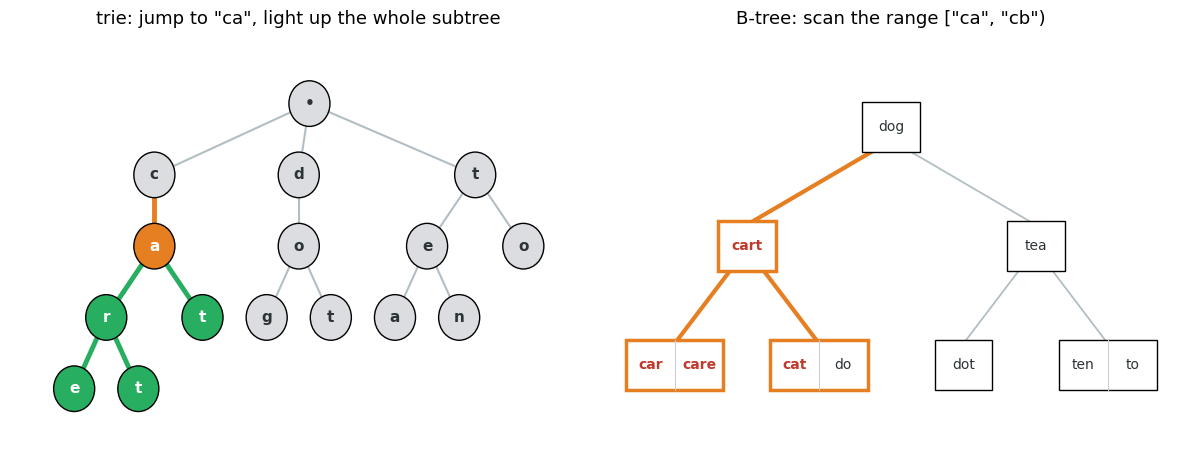

['car', 'care', 'cart', 'cat']


In [39]:
def trie_subtree(prefix):
    """All descendant paths of `prefix` that are present in the trie (including prefix itself)."""
    return {p for p in paths if p.startswith(prefix)}

def collect_prefix_matches(node, prefix, acc):
    for k in node.keys:
        if k.startswith(prefix):
            acc.append((id(node), k))
    for c in node.children:
        collect_prefix_matches(c, prefix, acc)

PREFIX = "ca"
trie_hits = trie_subtree(PREFIX)
bt_matches = []
collect_prefix_matches(word_bt.root, PREFIX, bt_matches)
bt_hit_nodes = {nid for nid, _ in bt_matches}
bt_hit_keys = {}
for nid, k in bt_matches:
    bt_hit_keys.setdefault(nid, set()).add(k)

fig4, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(12, 4.8))
draw_trie(ax4a, positions, children, paths, reuse=trie_subtree(PREFIX) - {PREFIX},
           new={PREFIX}, ends=ends_all & trie_hits,
           title=f'trie: jump to "{PREFIX}", light up the whole subtree')
draw_btree(ax4b, word_bt.root, highlight_nodes=bt_hit_nodes, highlight_keys=bt_hit_keys,
            title=f'B-tree: scan the range ["{PREFIX}", "cb")')
plt.tight_layout()
plt.show()
print(sorted(w for w in WORDS if w.startswith(PREFIX)))


## Scene 5 — A miss: searching for `"cap"`

`c → a` both exist, but there is no `p` child after `a`, the trie 
search fails right when it starts. 

In [40]:
MISS_QUERY = "cap"
miss_steps, miss_found, miss_fail_node = trie_search_steps(MISS_QUERY)
assert not miss_found

fig5, ax5 = plt.subplots(figsize=(9, 4.8))

miss_frames = len(miss_steps) + 1  # +1 to hold on the failure frame

def update_miss(i):
    if i < len(miss_steps):
        shown = set(miss_steps[:i + 1])
        draw_trie(ax5, positions, children, shown, reuse=shown - {""},
                   ends=ends_all & shown,
                   title=f'searching "{MISS_QUERY}": at node "{miss_steps[i] or chr(0x3b5)}"')
    else:
        shown = set(miss_steps)
        draw_trie(ax5, positions, children, shown, reuse=shown - {""},
                   ends=ends_all & shown, fail=miss_fail_node,
                   title=f'"{MISS_QUERY}" not found — no "{miss_fail_node[-1]}" child here')
        # draw a faint marker for the missing node at the position it *would* occupy
        x, y = positions[miss_steps[-1]]
        ax5.plot(x + 0.75, y - 1, marker='x', markersize=14, color=COLOR['fail'], mew=3, zorder=4)
        ax5.text(x + 0.75, y - 1.4, f'"{miss_fail_node}"?', ha='center', fontsize=9, color=COLOR['fail'])

ani5 = animation.FuncAnimation(fig5, update_miss, frames=miss_frames, interval=700)
show_animation(ani5, fig5)


## Part 2 — Where the trie struggles

Tries work best with prefixes, in other words when keys share structure. 
But if we store words with no overlaps, `apple`, `banana`, `kiwi`, `mango`, `zebra` 
every word will  single becomes a long chain of letters. 

Worse: in a real trie
implementation, every node typically reserves a child slot for *every*
character in the alphabet (26 of them, for lowercase English), whether or
not that child is ever used. We can't draw 26 slots per node without
turning the picture into noise, so instead each node gets a faint ring of
dots — one per unused letter — to make the wasted space visible without
drowning the real structure.


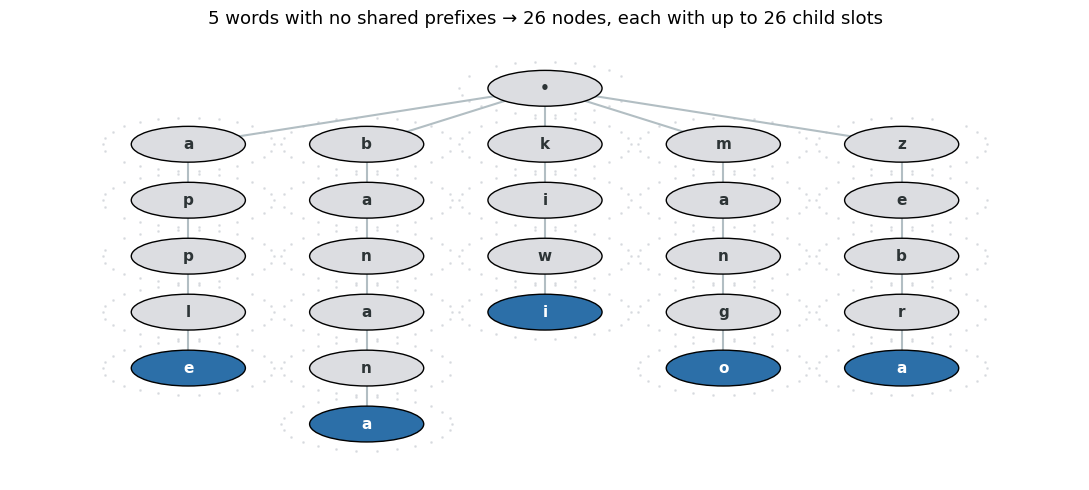

child-pointer slots allocated: 676, actually used: 25 (4%)


In [41]:
SPARSE_WORDS = ["apple", "banana", "kiwi", "mango", "zebra"]
ALPHABET = "abcdefghijklmnopqrstuvwxyz"

sparse_paths, sparse_ends, sparse_children = build_trie_paths(SPARSE_WORDS)
sparse_positions = layout_trie(sparse_children)

fig6, ax6 = plt.subplots(figsize=(11, 5))
draw_trie(ax6, sparse_positions, sparse_children, sparse_paths, ends=sparse_ends,
           title=f"{len(SPARSE_WORDS)} words with no shared prefixes → {len(sparse_paths)} nodes, "
                 f"each with up to 26 child slots")

# Faint ring of dots around every node: filled = real child, faint = unused slot.
for p in sparse_paths:
    x, y = sparse_positions[p]
    used = sparse_children.get(p, set())
    n = len(ALPHABET)
    for i, ch in enumerate(ALPHABET):
        angle = 2 * math.pi * i / n
        dx, dy = 0.48 * math.cos(angle), 0.48 * math.sin(angle)
        if ch in used:
            continue  # the real edge already shows this one
        ax6.plot(x + dx, y + dy, marker='.', markersize=2, color='#cfd3d8', alpha=0.6, zorder=0)

plt.tight_layout()
plt.show()

total_slots = len(sparse_paths) * 26
used_slots = sum(len(v) for v in sparse_children.values())
print(f"child-pointer slots allocated: {total_slots}, actually used: {used_slots} "
      f"({used_slots/total_slots:.0%})")


Now pack the exact same five words into a B-tree. Because a B-tree's
node size doesn't depend on an alphabet at all — it depends only on how
many *keys* you choose to pack per node — these five words fit into one or
two compact nodes with no wasted slots.


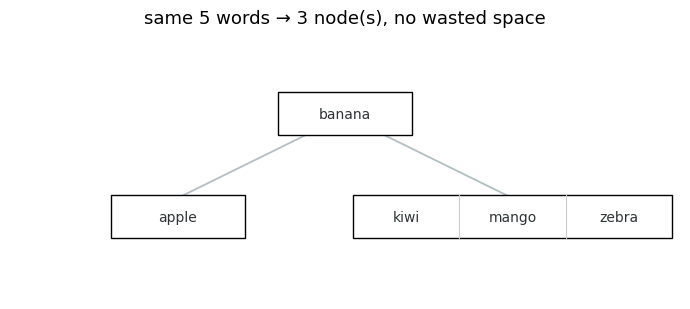

In [42]:
sparse_bt = BTree(order=4)
for w in SPARSE_WORDS:
    sparse_bt.insert(w)

def count_nodes(node):
    return 1 + sum(count_nodes(c) for c in node.children)

fig7, ax7 = plt.subplots(figsize=(7, 3.2))
draw_btree(ax7, sparse_bt.root,
            title=f"same {len(SPARSE_WORDS)} words → {count_nodes(sparse_bt.root)} node(s), no wasted space")
plt.tight_layout()
plt.show()


This is the core trade-off in one picture: the trie's per-character
nodes are *free* when keys share prefixes and *wasteful* when they don't.
The B-tree doesn't care either way, because it never allocated space for
an alphabet in the first place — only for the keys it was actually given.


## Part 3 — Where the B-tree shines: numbers

Numbers (and dates, IDs, floats — anything with a total order but no
shared "prefix" structure worth exploiting) are exactly what a trie
handles badly and a B-tree handles natively, because a B-tree only ever
needs `<` and `==`.

### Scene 6 — Sequential inserts, 1 through 15

Inserting keys *in order* is the worst case for triggering splits — every
new key lands at the right edge of the tree, so this animation shows
repeated splits cascading up the right side while the tree stays
perfectly balanced and grows **upward from the root**, one level at a
time. It's the most satisfying B-tree animation there is.


In [43]:
seq_bt = BTree(order=3)
for n in range(1, 16):
    seq_bt.insert(n)

fig8, ax8 = plt.subplots(figsize=(9, 5))

def update_seq_build(i):
    desc, root = seq_bt.snapshots[i]
    draw_btree(ax8, root, title=f"{desc}  ({i+1}/{len(seq_bt.snapshots)})")

ani8 = animation.FuncAnimation(fig8, update_seq_build, frames=len(seq_bt.snapshots), interval=350)
show_animation(ani8, fig8)


### Scene 8 — b-trees are short and wide!

Let's compute the `height = ceil(log_order(N))`of a b-tree.
And see how it will if 1 mln keys were inserted

In [51]:
def btree_height(n_keys, order):
    """Worst-case height of a B-tree holding n_keys keys, each internal node near-full."""
    if n_keys <= order - 1:
        return 1
    # Every level up roughly multiplies capacity by `order` (branching factor).
    return math.ceil(math.log(n_keys + 1, order))

N_VALUES = [10, 100, 1_000, 10_000, 100_000, 1_000_000]
ORDER = 100  # a realistic disk-page B-tree order, not our toy order-3 demo

heights = [btree_height(n, ORDER) for n in N_VALUES]
for n, h in zip(N_VALUES, heights):
    print(f"N={n:>9,}  height ≈ {h}")


N=       10  height ≈ 1
N=      100  height ≈ 2
N=    1,000  height ≈ 2
N=   10,000  height ≈ 3
N=  100,000  height ≈ 3
N=1,000,000  height ≈ 4


In [55]:
fig10, ax10 = plt.subplots(figsize=(8, 4.5))

def update_height(i):
    ax10.clear()
    xs = list(range(i + 1))
    ys = heights[:i + 1]
    ax10.plot(xs, ys, color=COLOR['end'], lw=2.5, marker='o', markersize=8,
               markerfacecolor=COLOR['end'], markeredgecolor='white', zorder=3)
    for x, y, n in zip(xs, ys, N_VALUES[:i + 1]):
        ax10.annotate(f"N={n:,}\nheight={y}", (x, y), textcoords="offset points",
                        xytext=(0, 14), ha='center', fontsize=8, color=COLOR['text_dark'])
    ax10.set_xlim(-0.5, len(N_VALUES) - 0.5)
    ax10.set_ylim(0, max(heights) + 1.5)
    ax10.set_xticks(range(len(N_VALUES)))
    ax10.set_xticklabels([f"{n:,}" for n in N_VALUES], rotation=20)
    ax10.set_xlabel("number of keys(N)")
    ax10.set_ylabel("tree height")
    ax10.set_title(f"B-tree height vs. N  (order {ORDER})")
    for spine in ['top', 'right']:
        ax10.spines[spine].set_visible(False)
    fig10.tight_layout()  # keeps the x-axis label from being cut off below the slanted tick labels

ani10 = animation.FuncAnimation(fig10, update_height, frames=len(N_VALUES), interval=900)
show_animation(ani10, fig10)


Going from 10 keys to a million is five orders of magnitude but the
tree only grew from 1 level to 4. That's the entire reason database
indexes are B-trees: a lookup on a billion-row table still only touches a
handful of nodes.

## Part 4 — Real-world examples

- **Trie → phone autocomplete.** Type `"ca"` into a contacts search bar and
  suggestions will appear immidiately 
- **B-tree → a database index.** `SELECT * FROM orders WHERE date BETWEEN
  '2026-03-01' AND '2026-05-31'` or `WHERE customer_id = 48213` are
  answered the way Scene 6/7 answered them: 

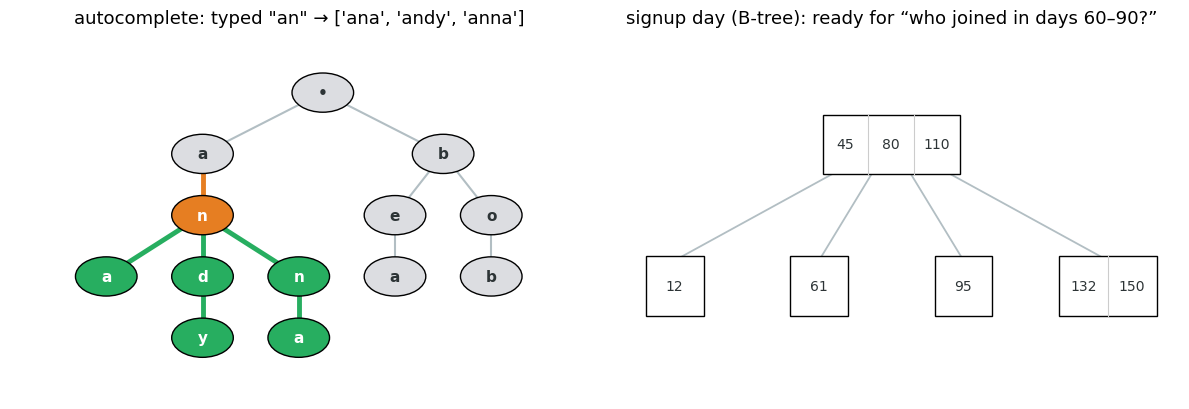

In [56]:
CONTACT_NAMES = ["ana", "anna", "andy", "bob", "bea"]
name_paths, name_ends, name_children = build_trie_paths(CONTACT_NAMES)
name_positions = layout_trie(name_children)

TYPED = "an"
typed_hits = {p for p in name_paths if p.startswith(TYPED)}

SIGNUP_DAYS = [12, 45, 61, 80, 95, 110, 132, 150]  # "days since app launch" for each contact
signup_bt = BTree(order=4)
for d in SIGNUP_DAYS:
    signup_bt.insert(d)

fig11, (ax11a, ax11b) = plt.subplots(1, 2, figsize=(12, 4.2))
draw_trie(ax11a, name_positions, name_children, name_paths,
           reuse=typed_hits - {TYPED}, new={TYPED}, ends=name_ends & typed_hits,
           title=f'autocomplete: typed "{TYPED}" → {sorted(w for w in CONTACT_NAMES if w.startswith(TYPED))}')
draw_btree(ax11b, signup_bt.root,
            title='signup day (B-tree): ready for “who joined in days 60–90?”')
plt.tight_layout()
plt.show()


## Wrap-up

| | Trie | B-tree |
|---|---|---|
| Unit of storage | one character | several whole keys |
| Best for | strings with shared structure (names, words, URLs, paths) | anything orderable (numbers, dates, IDs, strings too) |
| Prefix search | native — jump to a subtree | simulated as a range scan |
| Range search | awkward | native, especially with B+ leaf links |
| Memory | can be wasteful with a sparse alphabet and no shared prefixes | always compact; size depends only on key count |
| Height / cost driver | key length | log of key count (branching factor dependent) |

Neither structure is strictly better as they're optimized for different
questions. A trie answers "what starts with this?" in the time it takes
to read the prefix. A B-tree answers "what's near this, in sorted order?"
in a number of disk reads that barely grows even at enormous scale.
